Saving crop_yield.csv to crop_yield.csv
Dataset Shape: (19689, 10)

Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Multiple Linear Regression Results
Mean Absolute Error: 63.88493006993583
Mean Squared Error: 151851.13314417494
Root Mean Squared Error: 389.6808093095873
R2 Score: 0.8104798078643067
Training Time: 0.1648 seconds

Actual vs Predicted Values:
   Actual Yield  Predicted Yield
0      3.820000        12.616268
1      1.395357         0.822473
2      6.522727        -8.511940
3      0.812857       -14.742297
4      0.508000        -1.673957
5      0.358000        -8.625547
6      0.749091        -4.362059
7      1.835789        10.224322
8     75.314375       162.456339
9      1.775000        96.572534


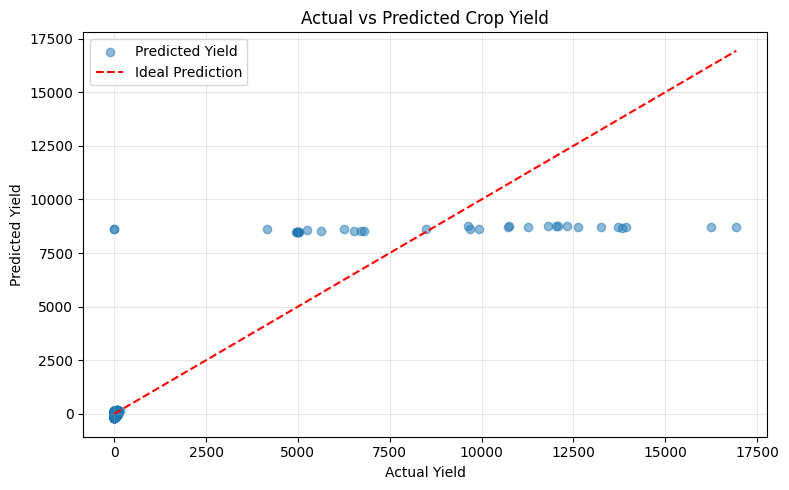

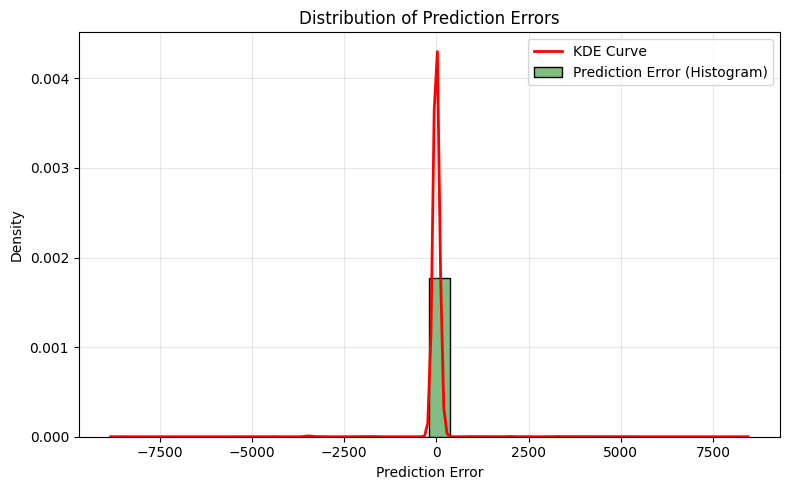


Crop Yield Prediction
Enter Crop Name: SWEET
Enter Crop Year: 2028
Enter Season: winter
Enter State: ap
Enter Cultivated Area: 3
Enter Annual Rainfall: 87
Enter Fertilizer Usage: 3
Enter Pesticide Usage: 4

Predicted Crop Yield: 156.9832713548712


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Upload Dataset
uploaded = files.upload()

df = pd.read_csv('crop_yield.csv')

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())


# 2. Data Cleaning
df = df.drop_duplicates()
df = df.dropna()


# 3. Feature Selection
X = df[['Crop', 'Crop_Year', 'Season', 'State',
        'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']]

y = df['Yield']


# 4. Feature Preprocessing
categorical_features = ['Crop', 'Season', 'State']

numerical_features = ['Crop_Year', 'Area', 'Annual_Rainfall',
                      'Fertilizer', 'Pesticide']

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('numerical', StandardScaler(), numerical_features)
    ]
)


# 5. Build Machine Learning Pipeline
model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])


# 6. Split Dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# 7. Train Model and Calculate Training Time
start_time = time.time()

model.fit(X_train, y_train)

end_time = time.time()

training_time = end_time - start_time


# 8. Predict Test Data
y_pred = model.predict(X_test)


# 9. Model Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMultiple Linear Regression Results")

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

print("Training Time:", round(training_time, 4), "seconds")


# 10. Actual vs Predicted Values
results = pd.DataFrame({
    'Actual Yield': y_test.values,
    'Predicted Yield': y_pred
})

print("\nActual vs Predicted Values:")
print(results.head(10))


# 11. Graph 1: Actual vs Predicted Crop Yield
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test, y_pred,
    alpha=0.5,
    label="Predicted Yield"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label="Ideal Prediction"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 12. Graph 2: Distribution of Prediction Errors
errors = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(
    errors,
    stat="density",
    bins=30,
    color="green",
    alpha=0.5,
    label="Prediction Error (Histogram)"
)

sns.kdeplot(
    errors,
    color="red",
    linewidth=2,
    label="KDE Curve"
)

plt.xlabel("Prediction Error")
plt.ylabel("Density")
plt.title("Distribution of Prediction Errors")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 13. Crop Yield Prediction for New Input
print("\nCrop Yield Prediction")

crop = input("Enter Crop Name: ")
year = int(input("Enter Crop Year: "))
season = input("Enter Season: ")
state = input("Enter State: ")
area = float(input("Enter Cultivated Area: "))
rainfall = float(input("Enter Annual Rainfall: "))
fertilizer = float(input("Enter Fertilizer Usage: "))
pesticide = float(input("Enter Pesticide Usage: "))


new_data = pd.DataFrame({
    'Crop': [crop],
    'Crop_Year': [year],
    'Season': [season],
    'State': [state],
    'Area': [area],
    'Annual_Rainfall': [rainfall],
    'Fertilizer': [fertilizer],
    'Pesticide': [pesticide]
})


prediction = model.predict(new_data)

print("\nPredicted Crop Yield:", prediction[0])
